# Lorenz '96 Two-Tier — Slow-Fast Multiscale Chaos

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/lorenz96t_simulation.ipynb)

*Moved from somax's tutorial series.*

The two-tier Lorenz '96 system couples a set of **slow** large-scale variables $X_k$ to a set of **fast** small-scale variables $Y_{j,k}$. It is the standard test bed for studying multiscale dynamics, sub-grid parameterisation and stochastic closures.

**What you'll learn:**

1. How slow and fast variables interact through coupling
2. How the Hovmöller diagram reveals the multiscale structure
3. How coupling strength changes the slow variables
4. How to differentiate through a multiscale simulation

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## Background

The system consists of $N_X$ slow variables $X_k$ and $N_J$ fast variables $Y_{j,k}$ per slow variable. As `Lorenz96t` implements it,

$$
\frac{\mathrm{d}X_k}{\mathrm{d}t} = (X_{k+1} - X_{k-2}) X_{k-1} - X_k + F - \frac{h c}{b} \sum_{j=1}^{N_J} Y_{j,k}
$$

$$
\frac{\mathrm{d}Y_{j,k}}{\mathrm{d}t} = -c b (Y_{j+1,k} - Y_{j-2,k}) Y_{j-1,k} - c Y_{j,k} + \frac{h c}{b} X_k
$$

where $k$ is cyclic over the slow ring, and $j$ is cyclic within each $k$, so the fast variables of one sector connect to their neighbours only through $X_k$.

| Parameter | Role | Standard value |
| --- | --- | --- |
| $F$ | external forcing on the slow variables | 18 |
| $h$ | coupling coefficient | 1 |
| $b$ | amplitude ratio, fast to slow | 10 |
| $c$ | time-scale ratio, fast to slow | 10 |

The fast variables evolve $c = 10$ times faster than the slow variables and have $b = 10$ times smaller amplitude. The coupling term $h c / b$ transfers energy between the scales.

### Symbols

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $X_k(t)$, $Y_{j,k}(t)$ | slow and fast variables | $\mathbb{R}$ |
| $\mathbf{X}$, $\mathbf{Y}$ | stacked slow and fast variables, the state | $\mathbb{R}^{N_X}$, $\mathbb{R}^{N_J N_X}$ |
| $N_X$, $N_J$ | number of slow variables, and of fast variables per slow variable | count |
| $\boldsymbol{\theta} = (F, h, b, c)$ | the model's differentiable parameters | $\mathbb{R}^{4}$ |
| $f(\mathbf{X}, \mathbf{Y}; \boldsymbol{\theta})$ | the right-hand side | $\mathbb{R}^{N_X + N_J N_X}$ |
| $t \in [0, t_1]$, $\Delta t$ | time, window end and time step | $\mathbb{R}$ |
| $N_T$ | number of saved snapshots | count |
| $\mathcal{L}$ | loss, minimised | $\mathbb{R}$ |
| $\boldsymbol{\lambda}(t)$ | adjoint state | $\mathbb{R}^{N_X + N_J N_X}$ |
| $N_{\mathcal{E}}$ | number of ensemble members | count |

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Create the model

We use $N_X = 36$ slow variables and $N_J = 10$ fast variables per slow variable, so 360 fast variables in total.

In [4]:
# Shapes: N_X = 36 slow variables; N_J = 10 fast variables per slow variable

num_slow = 36
num_fast = 10

# today (sesmax_core)
model = sxt.Lorenz96t.create(F=18.0, h=1.0, b=10.0, c=10.0)
print(model)

Lorenz96t(
  params=L96TParams(F=weak_f32[], h=weak_f32[], b=weak_f32[], c=weak_f32[])
)


## 2. Forward simulation

The fast variables require a small time step. We integrate for 2 time units and save at a moderate output rate.

In [5]:
# Shapes: N_X = 36; N_J = 10; N_T = 400 saved snapshots

end_time = 2.0
time_step = 0.0005

# today (sesmax_core)
initial_state = sxt.L96TState.init_state(ndims=(num_slow, num_fast), noise=0.01, b=10.0)

# tₖ = 0.005 k
save_times = jnp.arange(0.0, end_time, 0.005)  # → (N_T,)

# today (sesmax_core, diffrax)
solution = model.integrate(  # x → (N_T, N_X); y → (N_T, N_J N_X)
    initial_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
)
print(f"Slow variables: {solution.ys.x.shape}")
print(f"Fast variables: {solution.ys.y.shape}")

Slow variables: (400, 36)
Fast variables: (400, 360)


## 3. Slow and fast time series

The slow variables look like the single-tier system's oscillations, while the fast variables show rapid fluctuations.

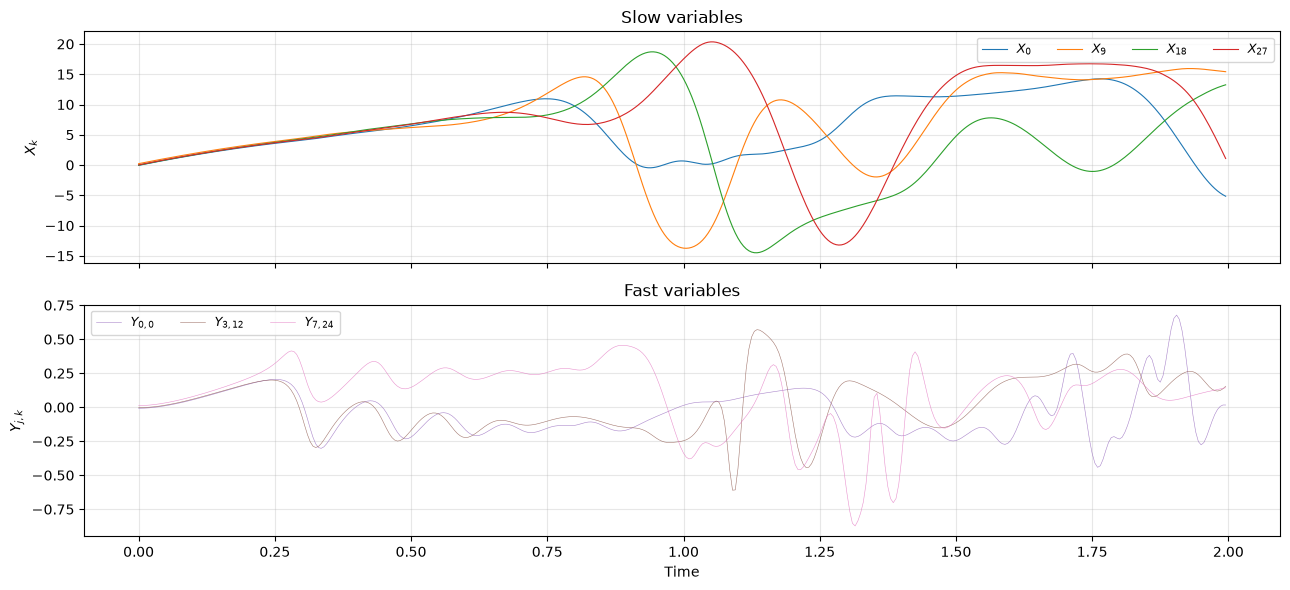

In [6]:
# Shapes: N_X = 36; N_J = 10; N_T = 400 saved snapshots

# Y_j,k from the flat fast state
fast_by_sector = einx.id(  # → (N_T, N_J, N_X)
    "time (j k) -> time j k", solution.ys.y, j=num_fast, k=num_slow
)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)

ax = axes[0]
for colour, position in enumerate([0, 9, 18, 27]):
    ax.plot(
        save_times,
        solution.ys.x[:, position],
        lw=0.8,
        color=f"C{colour}",
        label=f"$X_{{{position}}}$",
    )
ax.set_ylabel("$X_k$")
ax.set_title("Slow variables")
ax.legend(fontsize=9, ncol=4)
ax.grid(True, alpha=0.3)

ax = axes[1]
for colour, (fast, slow) in enumerate([(0, 0), (3, 12), (7, 24)]):
    ax.plot(
        save_times,
        fast_by_sector[:, fast, slow],
        lw=0.4,
        alpha=0.8,
        color=f"C{colour + 4}",
        label=f"$Y_{{{fast},{slow}}}$",
    )
ax.set_xlabel("Time")
ax.set_ylabel("$Y_{j,k}$")
ax.set_title("Fast variables")
ax.legend(fontsize=9, ncol=3)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Hovmöller diagrams: slow against fast

The slow-variable Hovmöller shows the familiar wave propagation. The fast-variable Hovmöller, averaged over the $j$ index, shows the small-scale activity alongside the large-scale pattern.

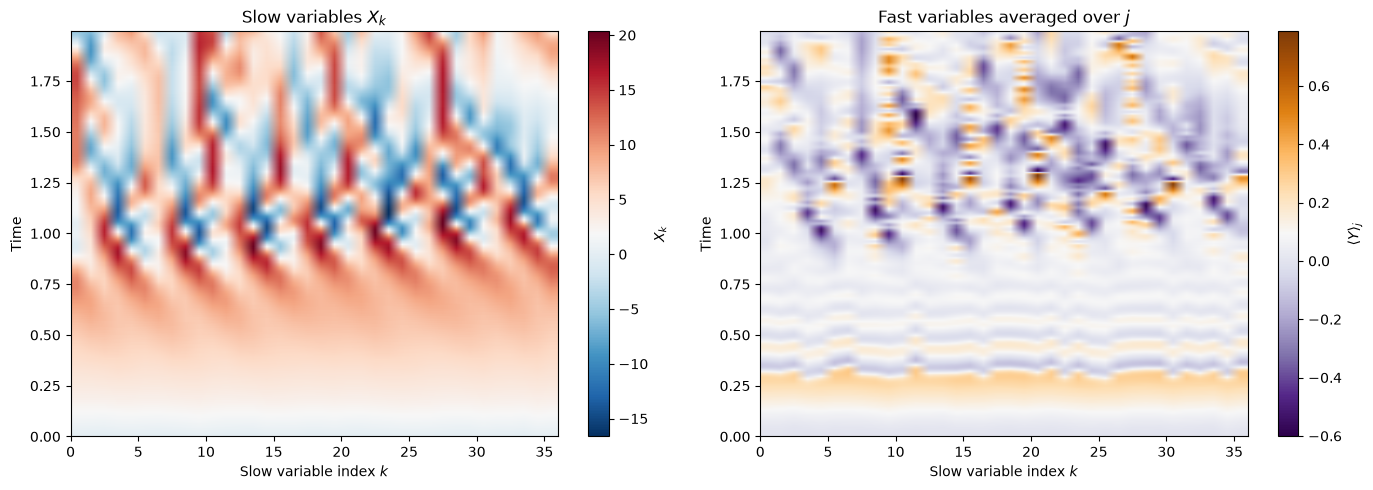

In [7]:
# Shapes: N_X = 36; N_J = 10; N_T = 400 saved snapshots

# (1 / N_J) ∑ⱼ Y_j,k
fast_average = einx.mean("time [j] k -> time k", fast_by_sector)  # → (N_T, N_X)

extent = [0, num_slow, float(save_times[0]), float(save_times[-1])]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

image = axes[0].imshow(
    solution.ys.x,
    aspect="auto",
    origin="lower",
    cmap="RdBu_r",
    extent=extent,
    interpolation="bilinear",
)
axes[0].set_xlabel("Slow variable index $k$")
axes[0].set_ylabel("Time")
axes[0].set_title("Slow variables $X_k$")
plt.colorbar(image, ax=axes[0], label="$X_k$")

image = axes[1].imshow(
    fast_average,
    aspect="auto",
    origin="lower",
    cmap="PuOr_r",
    extent=extent,
    interpolation="bilinear",
)
axes[1].set_xlabel("Slow variable index $k$")
axes[1].set_ylabel("Time")
axes[1].set_title(r"Fast variables averaged over $j$")
plt.colorbar(image, ax=axes[1], label=r"$\langle Y \rangle_j$")

plt.tight_layout()
plt.show()

## 5. Energy partition

The total energy splits between slow and fast components. The fast variables have $b$ times smaller amplitude and there are $N_J$ times as many of them, so the slow variables hold most of the energy, as the averages over the second half of the run show.

Slow energy over t >= 1: 1048.4
Fast energy over t >= 1: 18.1


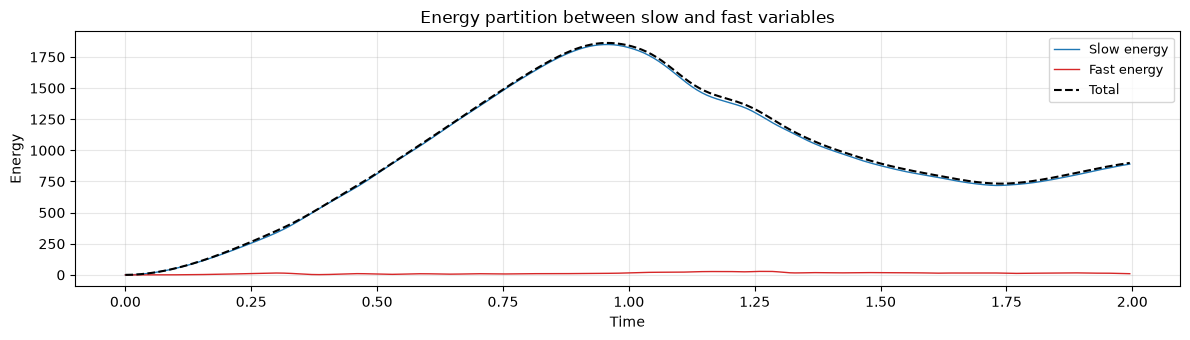

In [8]:
# Shapes: N_T = 400 saved snapshots

# E_X = ½ ∑ₖ X_k²
slow_energy = 0.5 * einx.sum("time [k] -> time", solution.ys.x**2)  # → (N_T,)
# E_Y = ½ ∑ⱼₖ Y_j,k²
fast_energy = 0.5 * einx.sum("time [jk] -> time", solution.ys.y**2)  # → (N_T,)

settled = save_times >= 1.0
print(f"Slow energy over t >= 1: {float(jnp.mean(slow_energy[settled])):.1f}")
print(f"Fast energy over t >= 1: {float(jnp.mean(fast_energy[settled])):.1f}")

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(save_times, slow_energy, lw=1, color="C0", label="Slow energy")
ax.plot(save_times, fast_energy, lw=1, color="C3", label="Fast energy")
total_energy = slow_energy + fast_energy  # → (N_T,)
ax.plot(save_times, total_energy, lw=1.5, color="k", ls="--", label="Total")
ax.set_xlabel("Time")
ax.set_ylabel("Energy")
ax.set_title("Energy partition between slow and fast variables")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Coupling strength

The coupling coefficient $h$ controls how strongly the fast variables feed back onto the slow variables. We compare $h = 0$, where the slow variables evolve as an uncoupled Lorenz '96 ring, with $h = 0.5$ and $h = 1$.

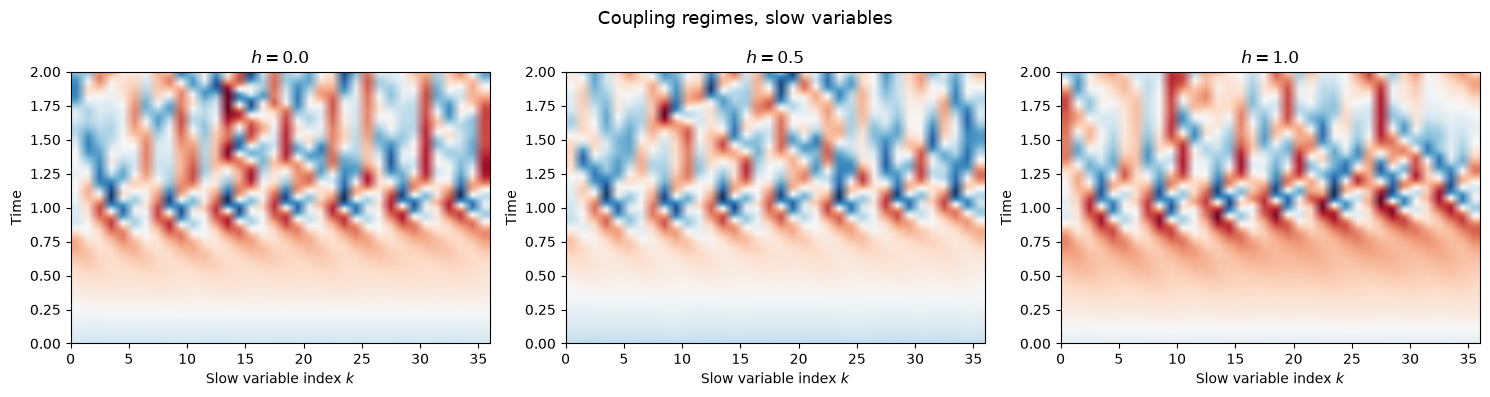

In [9]:
# Shapes: N_X = 36; N_T = 400 saved snapshots

couplings = [0.0, 0.5, 1.0]
coupling_solutions = {}
for coupling in couplings:
    # today (sesmax_core)
    coupled_model = sxt.Lorenz96t.create(F=18.0, h=coupling, b=10.0, c=10.0)
    # today (sesmax_core, diffrax)
    coupling_solutions[coupling] = coupled_model.integrate(  # x → (N_T, N_X)
        initial_state,
        t0=0.0,
        t1=end_time,
        dt=time_step,
        saveat=dfx.SaveAt(ts=save_times),
    ).ys.x

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coupling in zip(axes, couplings, strict=True):
    ax.imshow(
        coupling_solutions[coupling],
        aspect="auto",
        origin="lower",
        cmap="RdBu_r",
        extent=[0, num_slow, 0, end_time],
        interpolation="bilinear",
    )
    ax.set_xlabel("Slow variable index $k$")
    ax.set_ylabel("Time")
    ax.set_title(f"$h={coupling}$")
plt.suptitle("Coupling regimes, slow variables", fontsize=13)
plt.tight_layout()
plt.show()

## 7. Differentiation

Differentiating through a multiscale ODE is more demanding than through a single-scale system because the fast variables need many time steps. With $\Delta t = 5 \times 10^{-4}$, even a short window of $t_1 = 0.5$ takes 1,000 steps. The default `RecursiveCheckpointAdjoint` avoids storing all of those forward states; the [Lorenz '63 page](lorenz63_simulation.ipynb) compares the adjoint methods.

### 7a. Gradient with respect to the parameters

**Use case: parameter estimation.** All four parameters are differentiable. For the loss $\mathcal{L} = \lVert \mathbf{X}(t_1) \rVert^2$ the adjoint equations give:

$$
\nabla_{\boldsymbol{\theta}} \mathcal{L} = \int_{0}^{t_1} \boldsymbol{\lambda}(t)^\top \frac{\partial f}{\partial \boldsymbol{\theta}} \mathrm{d}t
$$

In [10]:
def window_loss(state, model):
    """ℒ = ‖X(t₁)‖², over a window of 0.5 time units."""
    # today (sesmax_core, diffrax)
    window = model.integrate(state, t0=0.0, t1=0.5, dt=time_step)  # x → (1, N_X)
    # ℒ = ∑ₖ X_k(t₁)²
    return jnp.sum(window.ys.x**2)  # → ()


# today (equinox)
# ∇_θ ℒ
parameter_gradient = eqx.filter_grad(lambda m: window_loss(initial_state, m))(model)
print(f"dL/dF = {float(parameter_gradient.params.F):.4f}")
print(f"dL/dh = {float(parameter_gradient.params.h):.4f}")
print(f"dL/db = {float(parameter_gradient.params.b):.4f}")
print(f"dL/dc = {float(parameter_gradient.params.c):.4f}")

dL/dF = 193.4378
dL/dh = -128.4100
dL/db = 39.7463
dL/dc = 0.3339


### 7b. Gradient with respect to the initial state

**Use case: 4D-Var.** Find the initial condition $(\mathbf{X}_0, \mathbf{Y}_0)$ that best fits observations. The gradient is the adjoint state at $t = 0$, $\boldsymbol{\lambda}(0)$. In practice one often assimilates only the slow variables and lets the fast variables spin up.

In [11]:
# today (jax)
# ∇_(X₀, Y₀) ℒ
state_gradient = jax.grad(window_loss)(initial_state, model)  # x, y → like the state

# ‖∇_X₀ ℒ‖₂
slow_norm = jnp.sqrt(jnp.sum(state_gradient.x**2))  # → ()
# ‖∇_Y₀ ℒ‖₂
fast_norm = jnp.sqrt(jnp.sum(state_gradient.y**2))  # → ()
print(f"dL/d(X0) shape: {state_gradient.x.shape}, norm: {float(slow_norm):.4f}")
print(f"dL/d(Y0) shape: {state_gradient.y.shape}, norm: {float(fast_norm):.4f}")

dL/d(X0) shape: (36,), norm: 52.9540
dL/d(Y0) shape: (360,), norm: 1425.0935


### 7c. Joint gradient: parameters and state

**Use case: joint estimation.** Optimise the initial condition and all the parameters together, in one backward pass.

In [12]:
# today (jax)
# (∇_(X₀, Y₀) ℒ, ∇_θ ℒ)
joint_state, joint_model = jax.grad(window_loss, argnums=(0, 1))(initial_state, model)

print(f"dL/dF         = {float(joint_model.params.F):.4f}")
print(f"dL/dh         = {float(joint_model.params.h):.4f}")
print(f"dL/d(X0) norm = {float(jnp.sqrt(jnp.sum(joint_state.x**2))):.4f}")
print(f"dL/d(Y0) norm = {float(jnp.sqrt(jnp.sum(joint_state.y**2))):.4f}")

dL/dF         = 193.4378
dL/dh         = -128.4100
dL/d(X0) norm = 52.9540
dL/d(Y0) norm = 1425.0935


## 8. Ensemble divergence

We launch 20 ensemble members and track how the slow-variable spread grows over time.

Spread at t = 0: 0.096, at t = 2: 6.139


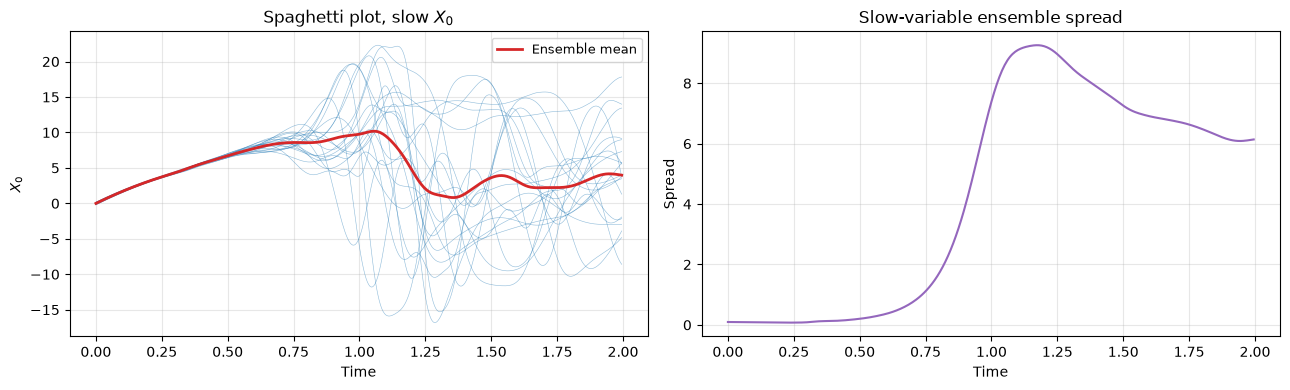

In [13]:
# Shapes: N_E = 20 members; N_X = 36; N_J = 10; N_T = 400 saved snapshots

num_members = 20
slow_key, fast_key = jax.random.split(jax.random.key(7))

# X₀⁽ᵉ⁾ ~ 𝒩(0, 0.1² I)
slow_members = 0.1 * jax.random.normal(slow_key, (num_members, num_slow))
# Y₀⁽ᵉ⁾ ~ 𝒩(0, 0.01² I)
fast_members = 0.01 * jax.random.normal(fast_key, (num_members, num_fast * num_slow))
# today (sesmax_core)
ensemble_states = sxt.L96TState(x=slow_members, y=fast_members)


def integrate_member(member_state):
    # today (sesmax_core, diffrax)
    return model.integrate(
        member_state,
        t0=0.0,
        t1=end_time,
        dt=time_step,
        saveat=dfx.SaveAt(ts=save_times),
    )


# today (equinox)
ensemble = eqx.filter_vmap(integrate_member)(ensemble_states)  # x → (N_E, N_T, N_X)

# X̄(t) = (1 / N_E) ∑ₑ X⁽ᵉ⁾(t)
ensemble_mean = einx.mean("[member] time k -> time k", ensemble.ys.x)  # → (N_T, N_X)
# var⁽ᵉ⁾[X_k(t)]
variance = einx.var("[member] time k -> time k", ensemble.ys.x)  # → (N_T, N_X)
# s(t) = √(mean over k of var⁽ᵉ⁾[X_k(t)])
spread = jnp.sqrt(einx.mean("time [k] -> time", variance))  # → (N_T,)
print(f"Spread at t = 0: {float(spread[0]):.3f}, at t = 2: {float(spread[-1]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
for member in range(num_members):
    ax.plot(save_times, ensemble.ys.x[member, :, 0], lw=0.4, alpha=0.5, color="C0")
ax.plot(save_times, ensemble_mean[:, 0], lw=2, color="C3", label="Ensemble mean")
ax.set_xlabel("Time")
ax.set_ylabel("$X_0$")
ax.set_title("Spaghetti plot, slow $X_0$")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(save_times, spread, lw=1.5, color="C4")
ax.set_xlabel("Time")
ax.set_ylabel("Spread")
ax.set_title("Slow-variable ensemble spread")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Summary

| Concept | sesmax API |
| --- | --- |
| Create a model | `Lorenz96t.create(F=18, h=1, b=10, c=10)` |
| Initial condition | `L96TState.init_state(ndims=(36, 10))` |
| Forward simulation | `model.integrate(state0, t0, t1, dt)` |
| Gradient with respect to the parameters | `eqx.filter_grad(loss)(model)`, all four |
| Gradient with respect to the state | `jax.grad(loss)(state0)` |
| Joint gradient | `jax.grad(loss, argnums=(0, 1))(state0, model)` |
| Ensemble | `eqx.filter_vmap(integrate_member)(batch_states)` |

- The fast variables evolve $c = 10$ times faster than the slow variables, which requires a small time step, $\Delta t = 5 \times 10^{-4}$ here.
- Coupling ($h > 0$) feeds the fast variables back into the slow dynamics.
- This system is the standard test bed for learned sub-grid parameterisations, which replace the fast variables with a closure.